In [1]:
import sys, os
sys.path.append(os.path.abspath('..'))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML

from models.qutip_model import QutipFermiHubbard
from models.qilisdk_model import QilisdkFermiHubbard
from src.plots import plot_chain_animation

In [2]:
backend = 'qutip'  # 'qutip' or 'qilisdk'

chain_length = 5

gx = 1
gz = 5
e = 0
J = 25
T = 15.0
dt = 0.01

nsteps = int(T/dt)
model_qutip = QutipFermiHubbard(chain_length, gx, gz, e, T, nsteps, J=J, mode="dw")

model_qutip.place_entangled_pair('up', 0, 'up', 1)
model_qutip.place_single_excitation('down', chain_length-1)
#model_qutip.flip_chain('down')

IndexError: list index out of range

In [47]:
pauli_strings = ['Z', 'ZZ']
result, measurements = model_qutip.run(pauli_strings=pauli_strings)


In [48]:
anim, fig = plot_chain_animation(measurements['Z'])

plt.close(fig)
HTML(anim.to_jshtml())

<Figure size 1000x600 with 0 Axes>

In [49]:
anim, fig = plot_chain_animation(measurements['ZZ'])

plt.close(fig)
HTML(anim.to_jshtml())

<Figure size 1000x600 with 0 Axes>

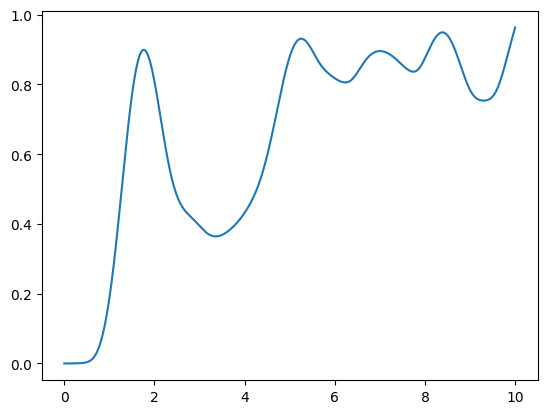

In [17]:
entropy = model_qutip.calculate_von_neumann_entropy(result.states)
plt.plot(np.linspace(0, T, nsteps), entropy)

In [53]:
import sys, os
sys.path.append(os.path.abspath('..'))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML

from models.qutip_model import QutipFermiHubbard
from models.qilisdk_model import QilisdkFermiHubbard
from src.plots import plot_chain_animation

backend = 'qutip'  # 'qutip' or 'qilisdk'

chain_length = 5

gx = 1
gz_list = np.linspace(-10, 10, 201)
e = 0
J = 25
T = 15.0
dt = 0.01
entropies = []


nsteps = int(T/dt)

for gz in gz_list:
    model_qutip = QutipFermiHubbard(chain_length, gx, gz, e, T, nsteps, J=J, mode="dw")
    model_qutip.place_entangled_pair('up', 0, 'up', 1)
    model_qutip.place_single_excitation('down', chain_length-1)
    model_qutip.flip_chain('down')
    pauli_strings = None
    result, measurements = model_qutip.run(pauli_strings=pauli_strings)
    entropies.append(model_qutip.calculate_von_neumann_entropy(result.states)) 
    

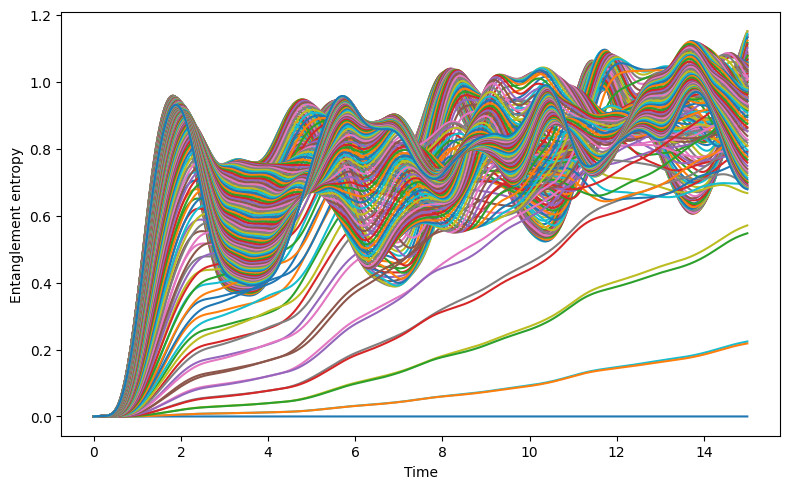

In [54]:
t = np.linspace(0, T, nsteps)


plt.figure(figsize=(8, 5))
for gz, S in zip(gz_list, entropies):
    plt.plot(t, S, label=f'gz={gz:.2f}')
plt.xlabel('Time')
plt.ylabel('Entanglement entropy')
#plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

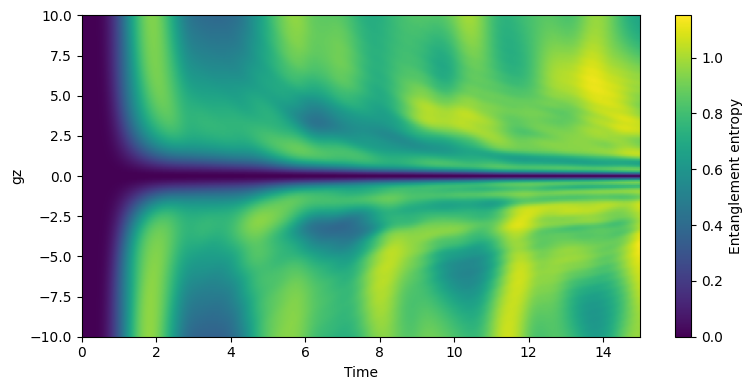

In [55]:
S = np.array(entropies)  # shape: (n_gz, n_time)

plt.figure(figsize=(8, 4))
plt.imshow(S, aspect='auto', origin='lower',
           extent=[t[0], t[-1], gz_list[0], gz_list[-1]])
plt.colorbar(label='Entanglement entropy')
plt.xlabel('Time')
plt.ylabel('gz')
plt.tight_layout()
plt.show()

In [ ]:
gx_list = np.linspace(0, 10, 21)
gz_list = np.linspace(0, 10, 21)
T = 10.0
dt = 0.01
nsteps = int(T/dt) - 1

S_final = np.zeros((len(gz_list), len(gx_list)))

for i, gz in enumerate(gz_list):
    print(i)
    for j, gx in enumerate(gx_list):
        model_qutip = QutipFermiHubbard(chain_length, gx, gz, e, T, nsteps, J=J, mode="dw")
        model_qutip.place_single_excitation('up', 0)
        model_qutip.place_single_excitation('down', chain_length) #remove -1 to chain_length when in dw
        pauli_strings = None
        result, measurements = model_qutip.run(pauli_strings=pauli_strings)
        S_final[i, j] = model_qutip.calculate_von_neumann_entropy([result.states[-1]])

plt.figure(figsize=(6, 5))
plt.imshow(S_final, aspect='auto', origin='lower',
           extent=[gx_list[0], gx_list[-1], gz_list[0], gz_list[-1]])
plt.colorbar(label='Entanglement entropy at T')
plt.xlabel('gx')
plt.ylabel('gz')
plt.tight_layout()
plt.show()

0


/var/folders/wh/28dwfv8x0qzfwl1_0pyzvs6h0000gp/T/ipykernel_36742/2061061215.py:17: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  S_final[i, j] = model_qutip.calculate_von_neumann_entropy([result.states[-1]])


1
2
3
4
5
6
7
8
9
10
11
12


ValueError: Function to integrate must not return a tuple.

In [6]:
stride = 1  # animate every stride-th timestep

gx_list = np.linspace(0, 10, 51)
gz_list = np.linspace(0, 10, 51)

S = np.zeros((nsteps, len(gz_list), len(gx_list)))

stride = 1  # animate every stride-th timestep


for i, gz in enumerate(gz_list):
    for j, gx in enumerate(gx_list):
        model_qutip = QutipFermiHubbard(chain_length, gx, gz, e, T, nsteps, J=J, mode="dw")
        model_qutip.place_single_excitation('up', 0)
        model_qutip.place_single_excitation('down', 0) #remove -1 to chain_length when in dw
        pauli_strings = None
        result, measurements = model_qutip.run(pauli_strings=pauli_strings)
        S[:, i, j] = model_qutip.calculate_von_neumann_entropy(result.states)

In [7]:
filename = "0-N_long_range_dw"
np.save(f"../../experiments/{filename}", S)

In [8]:
from matplotlib.animation import FuncAnimation
S = np.load("../../experiments/0-N_long_range_dw.npy")
t= range(nsteps)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(S[0], aspect='auto', origin='lower', vmin=S.min(), vmax=S.max(),
               extent=[gx_list[0], gx_list[-1], gz_list[0], gz_list[-1]])
plt.colorbar(im, ax=ax, label='Entanglement entropy')
ax.set_xlabel('gx')
ax.set_ylabel('gz')
title = ax.set_title(f't = {t[0]:.2f}')

def update(k):
    frame = k * stride
    im.set_data(S[frame])
    title.set_text(f't = {t[frame]:.2f}')
    return im, title

frames = nsteps // stride
anim = FuncAnimation(fig, update, frames=frames, interval=50, blit=False)
plt.close(fig)
HTML(anim.to_jshtml())